In [1]:
import matplotlib.pyplot as plt
import torch

from specter.image import normalize_particles
from specter.imaging import CTF, Exposure, Poses, Specimen
from specter.pdb import PDB
from specter.progress import track

## Get atoms and coordinates

In [2]:
pdb = PDB("6e9d")

In [3]:
n = 300
dx = 1
coordinates = pdb.coordinates.clone()
atomic_numbers = pdb.atomic_numbers.clone()

## Generate images

`Specimen.from_atoms` keeps the atoms and renders them afresh at every pose: the atoms are rotated rather than the potential, so each image is a differentiable function of the coordinates. Bare coordinates carry no bonds, so every atom takes its element's scattering factors.

In [4]:
n_particles = 10
voltage = 300  # kV
dose_per_angstrom = 20  # e-/A^2
cs = 2.0  # mm, spherical aberration; typical values are 1-3 mm.
alpha = 0.1

In [5]:
# random poses, shifted by up to 2 A along each axis; set shift=0 for none
poses = Poses.random(n_particles, shift=2.0)
# random defocus, uniform per particle
ctf = CTF.sample(n_particles, defocus=[5000.0, 15000.0], cs=cs)
exposure = Exposure(dose_per_angstrom)

In [6]:
device = "cuda:0"  # choose cpu if you run out of cuda memory.

In [7]:
specimen = Specimen.from_atoms(
    coordinates.to(device), atomic_numbers, dx, n, conv_backend="conv3d"
)
# Crowding: neighbouring copies at least this far apart, drawn per particle.
# specimen = specimen.crowd(min_distance=pdb.max_diameter)

# Ice: "gd" samples the bundled library of relaxed ice; thickness 0 is the
# particle box's own depth.
specimen = specimen.solvate(model="gd", thickness=0)

In [8]:
# Multislice and Poisson noise give images closest to experimental ones.
scatter = dict(
    scattering_model="multislice",  # 'multislice', 'firstborn', 'projection', 'ctf'
    ews_curvature_sign="positive",
    alpha=alpha,
    pad_fft=True,  # avoids edge artefacts, most of all with crowding
)

images = []
batchsize = 5  # set higher or lower for faster/slower generation.
with torch.no_grad():
    for start in track(
        range(0, n_particles, batchsize), description="Generating images"
    ):
        i = slice(start, start + batchsize)
        waves = specimen.scatter(poses[i], voltage=voltage, **scatter)
        image = waves.apply_ctf(ctf[i]).intensity()
        image = image.detect(exposure, noise="poisson")
        images.append(image.array.cpu())

images = torch.cat(images)
images.shape

Generating images:   0%|          | 0/2 [00:00<?, ?it/s]

torch.Size([10, 300, 300])

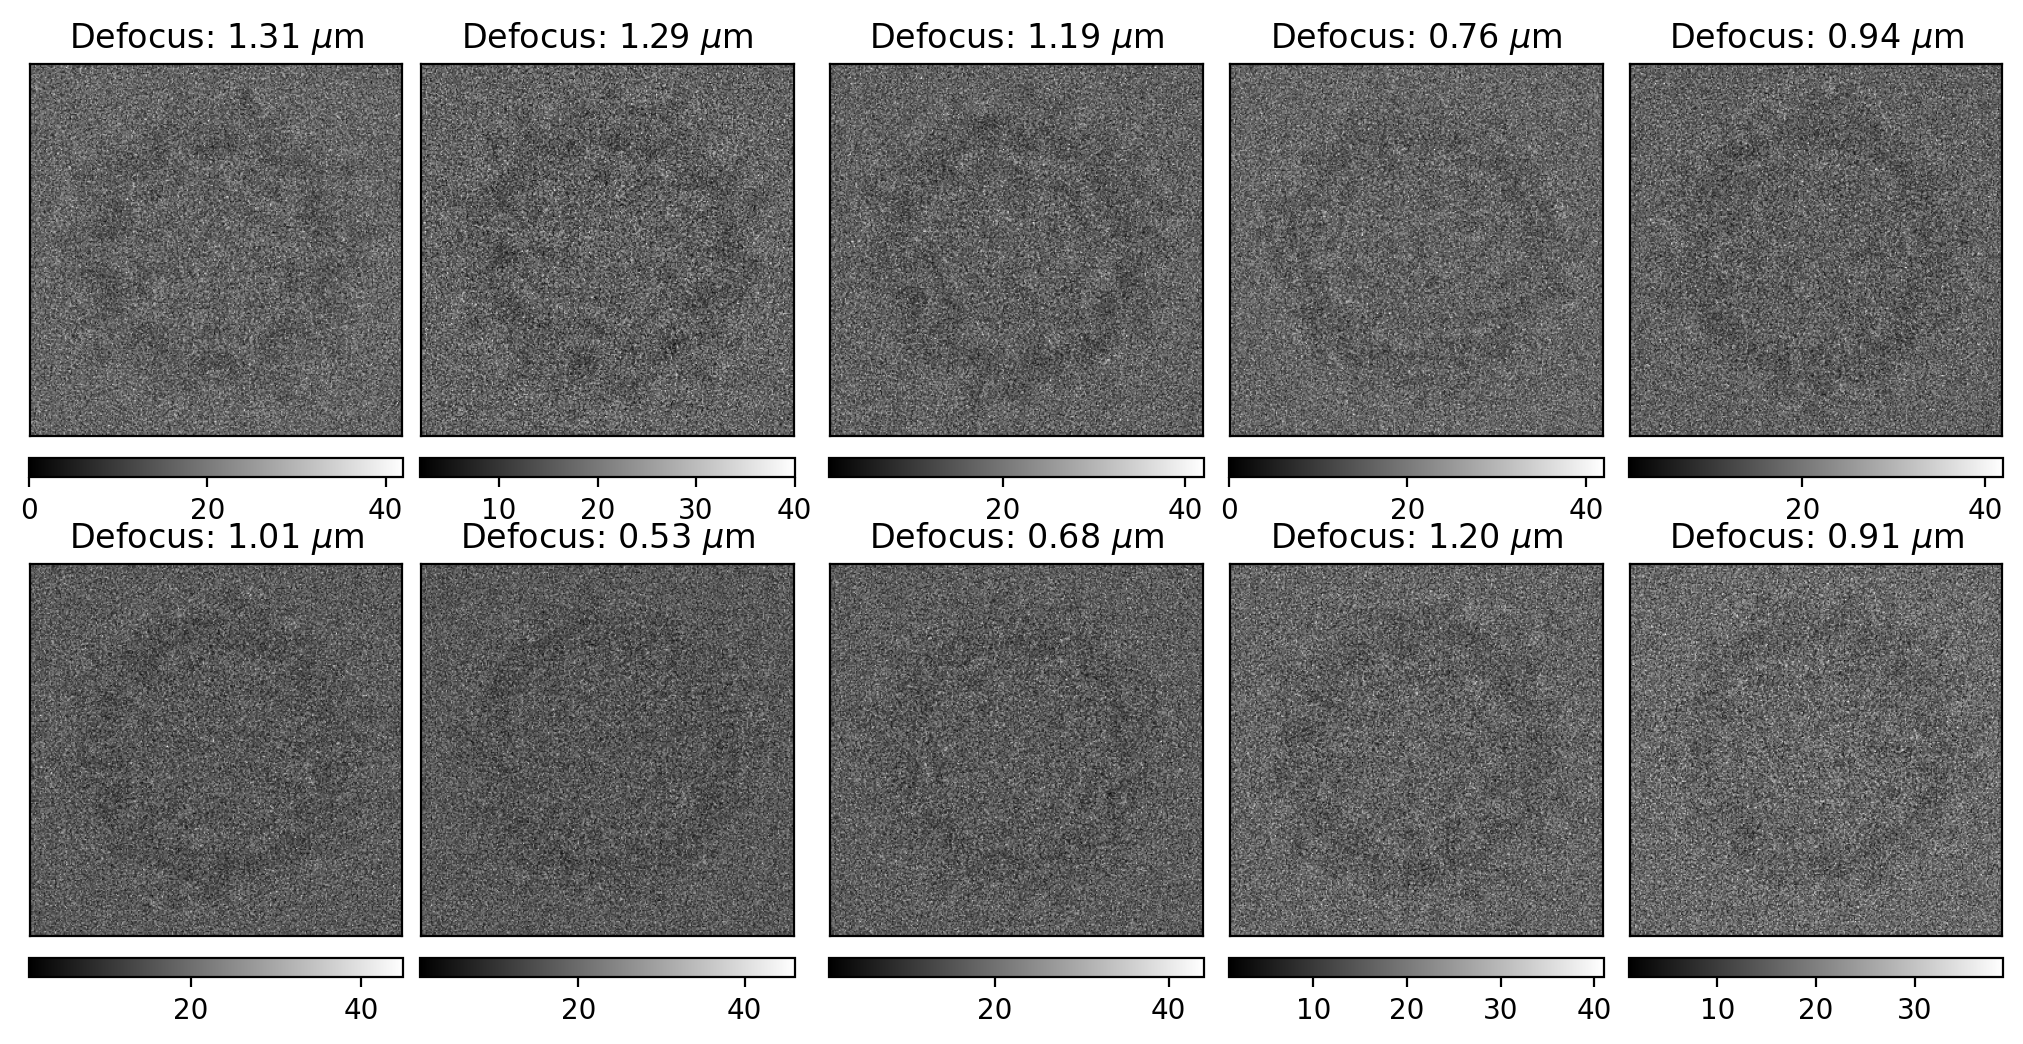

In [9]:
fig, axes = plt.subplots(2, 5, dpi=200, constrained_layout=True, figsize=(10, 5))
for i, ax in enumerate(axes.ravel()):
    im = ax.imshow(images[i], cmap="grey")
    ax.set(xticks=[], yticks=[])
    ax.set_title(rf"Defocus: {ctf.params['dfu'][i] / 10000:.2f} $\mu$m")
    fig.colorbar(im, ax=ax, location="bottom")
plt.show()

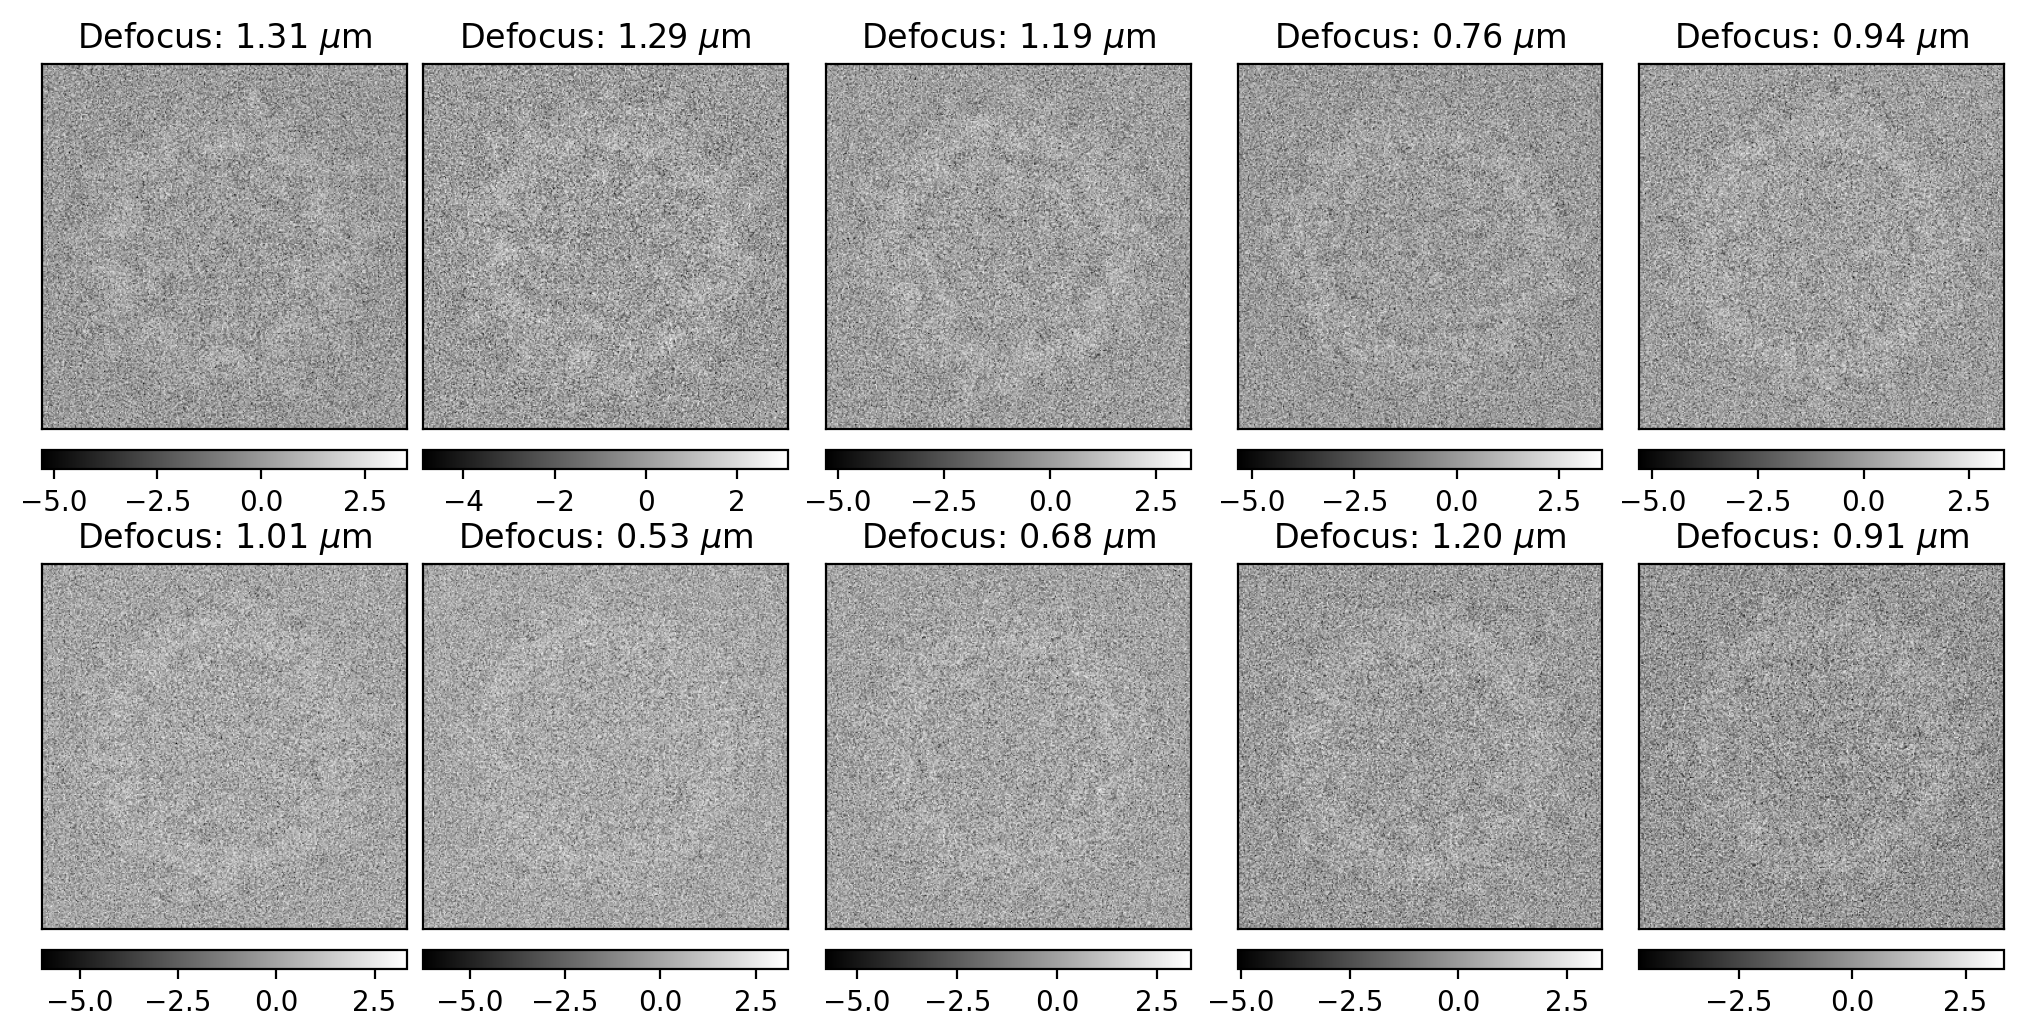

In [10]:
# normalize and flip sign
particles, means, stds = normalize_particles(images)
particles = -particles

fig, axes = plt.subplots(2, 5, dpi=200, constrained_layout=True, figsize=(10, 5))
for i, ax in enumerate(axes.ravel()):
    im = ax.imshow(particles[i], cmap="grey")
    ax.set(xticks=[], yticks=[])
    ax.set_title(rf"Defocus: {ctf.params['dfu'][i] / 10000:.2f} $\mu$m")
    fig.colorbar(im, ax=ax, location="bottom")
plt.show()